# 03 · Data Structures

**Module 01 — Python Foundations for Data Science**

---

## What you will learn

1. The four built-in collections, and how to pick between them **by complexity**, not by habit.
2. Why `x in my_set` is thousands of times faster than `x in my_list` — measured, not asserted.
3. The `collections` module: `Counter`, `defaultdict`, `deque`, `namedtuple`.
4. Comprehensions — the idiom that replaces most of your `for` loops.
5. Sorting with key functions, and why sort stability matters for data work.
6. Unpacking and star expressions.

**Estimated time:** 90 minutes

In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np

from dstoolkit import setup_plot_style
from dstoolkit.plotting import COLORS

setup_plot_style()

## 1. The map

Before the details, the summary you should internalise. Almost every
performance problem in day-to-day Python traces back to reading the
"Membership" row of this table wrongly.

![Choosing a built-in collection](../../../assets/images/data_structures_comparison.png)

## 2. Lists — the ordered workhorse

A `list` is a mutable, ordered sequence. Internally it is an **array of pointers**
to objects, which explains all of its performance characteristics.

In [2]:
# Lists hold anything, including mixed types — though in practice, homogeneous
# lists are what you want (and what NumPy will demand in Module 02).
revenues = [1200.50, 980.00, 1540.75, 620.25, 2100.00]

print(f"list          : {revenues}")
print(f"len           : {len(revenues)}")
print(f"sum           : {sum(revenues):,.2f}")
print(f"min / max     : {min(revenues):,.2f} / {max(revenues):,.2f}")

list          : [1200.5, 980.0, 1540.75, 620.25, 2100.0]
len           : 5
sum           : 6,441.50
min / max     : 620.25 / 2,100.00


### Slicing: `[start:stop:step]`

`stop` is always **excluded**. This is deliberate: it makes `len(x[a:b]) == b - a`,
and it makes `x[:n] + x[n:] == x` true for every `n`.

In [3]:
data = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

print(f"data          : {data}")
print(f"data[2:5]     : {data[2:5]}        ← indexes 2, 3, 4")
print(f"data[:3]      : {data[:3]}              ← first three")
print(f"data[-3:]     : {data[-3:]}              ← last three")
print(f"data[::2]     : {data[::2]}     ← every second element")
print(f"data[::-1]    : {data[::-1]}  ← reversed")

# A slice always produces a NEW list — this is the standard shallow-copy idiom.
copy_of_data = data[:]
print(f"\ndata[:] is data : {copy_of_data is data}   ← a genuine copy")

data          : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
data[2:5]     : [2, 3, 4]        ← indexes 2, 3, 4
data[:3]      : [0, 1, 2]              ← first three
data[-3:]     : [7, 8, 9]              ← last three
data[::2]     : [0, 2, 4, 6, 8]     ← every second element
data[::-1]    : [9, 8, 7, 6, 5, 4, 3, 2, 1, 0]  ← reversed

data[:] is data : False   ← a genuine copy


### The methods worth knowing

> [!WARNING]
> Mutating methods return `None`, not the list. `sorted_list = my_list.sort()`
> assigns `None` — a mistake almost everyone makes at least once.

In [4]:
items = [3, 1, 4, 1, 5]

result = items.sort()          # sorts IN PLACE and returns None
print(f"items.sort() returned : {result}")
print(f"items is now          : {items}")

# When you want a new sorted list and the original preserved, use `sorted()`.
original = [3, 1, 4, 1, 5]
new_list = sorted(original)
print(f"\nsorted(original)      : {new_list}")
print(f"original              : {original}   ← untouched")

items.sort() returned : None
items is now          : [1, 1, 3, 4, 5]

sorted(original)      : [1, 1, 3, 4, 5]
original              : [3, 1, 4, 1, 5]   ← untouched


In [5]:
# The in-place mutators, for reference.
demo = [1, 2, 3]
demo.append(4)                 # add one item to the end          — O(1)
demo.extend([5, 6])            # add many items                   — O(k)
demo.insert(0, 0)              # insert at a position             — O(n), shifts everything
demo.remove(3)                 # delete the first matching VALUE  — O(n)
popped = demo.pop()            # remove and return the last item  — O(1)

print(f"after mutations : {demo}")
print(f"popped          : {popped}")
print(f"count of 1      : {demo.count(1)}")
print(f"index of 2      : {demo.index(2)}")

after mutations : [0, 1, 2, 4, 5]
popped          : 6
count of 1      : 1
index of 2      : 2


## 3. Tuples — immutable, and more than "a read-only list"

Tuples are used for two distinct purposes, and conflating them causes confusion:

1. **Records** — a fixed set of fields where *position has meaning* (`(lat, lon)`).
2. **Immutability** — when you need a sequence that can be a `dict` key or a `set` member.

In [6]:
point = (-23.55, -46.63)       # (latitude, longitude) — position carries meaning

# Unpacking is the idiomatic way to read a record.
latitude, longitude = point
print(f"latitude {latitude}, longitude {longitude}")

# Tuples are hashable (if their contents are), so they can be dict keys.
# This is genuinely useful for sparse, multi-dimensional lookups.
city_populations = {
    ("Brazil", "Sao Paulo"): 12_400_000,
    ("Brazil", "Rio de Janeiro"): 6_700_000,
    ("Japan", "Tokyo"): 13_960_000,
}
print(f"\nlookup by composite key : {city_populations[('Japan', 'Tokyo')]:,}")

# A list cannot do this.
try:
    {["Brazil", "Sao Paulo"]: 1}
except TypeError as exc:
    print(f"list as a key           : TypeError — {exc}")

latitude -23.55, longitude -46.63

lookup by composite key : 13,960,000
list as a key           : TypeError — unhashable type: 'list'


> [!NOTE]
> **Immutable does not mean "deeply frozen".** A tuple guarantees its *references*
> never change; it says nothing about the objects those references point to.

In [7]:
nested = ([1, 2], "fixed")
nested[0].append(3)            # allowed — we mutate the LIST, not the tuple
print(f"nested : {nested}")

try:
    nested[0] = [9, 9]         # not allowed — this would rebind a tuple slot
except TypeError as exc:
    print(f"rebinding a slot : TypeError — {exc}")

nested : ([1, 2, 3], 'fixed')
rebinding a slot : TypeError — 'tuple' object does not support item assignment


## 4. Dictionaries — the most important structure in Python

A `dict` maps **hashable keys** to arbitrary values, with **O(1)** average lookup.
Since Python 3.7 it preserves insertion order.

In [8]:
customer = {
    "id": 1042,
    "name": "Ana Silva",
    "channel": "organic",
    "spend": 245.80,
}

print(f"dict        : {customer}")
print(f"keys        : {list(customer.keys())}")
print(f"values      : {list(customer.values())}")

# Iterate over key/value pairs with .items() — the idiomatic loop.
print("\nitems():")
for key, value in customer.items():
    print(f"  {key:<10} {value}")

dict        : {'id': 1042, 'name': 'Ana Silva', 'channel': 'organic', 'spend': 245.8}
keys        : ['id', 'name', 'channel', 'spend']
values      : [1042, 'Ana Silva', 'organic', 245.8]

items():
  id         1042
  name       Ana Silva
  channel    organic
  spend      245.8


### Safe access: `.get()` and `.setdefault()`

Indexing a missing key raises `KeyError`. In data work, where a field may simply
be absent from some records, that is usually not what you want.

In [9]:
record = {"id": 7, "spend": 100.0}

# ✘ Raises on a missing key.
try:
    record["channel"]
except KeyError as exc:
    print(f"record['channel'] : KeyError({exc})")

# ✔ Returns a default instead.
print(f"record.get('channel')            : {record.get('channel')}")
print(f"record.get('channel', 'unknown') : {record.get('channel', 'unknown')}")

# `.setdefault` returns the value, inserting the default first if absent.
record.setdefault("channel", "unknown")
print(f"\nafter setdefault : {record}")

record['channel'] : KeyError('channel')
record.get('channel')            : None
record.get('channel', 'unknown') : unknown

after setdefault : {'id': 7, 'spend': 100.0, 'channel': 'unknown'}


### Merging dictionaries

The `|` operator (Python 3.9+) is the cleanest way to merge. Later keys win —
which makes it perfect for layering configuration over defaults.

In [10]:
defaults = {"model": "linear", "alpha": 0.1, "max_iter": 100}
overrides = {"alpha": 0.5}

config = defaults | overrides
print(f"defaults  : {defaults}")
print(f"overrides : {overrides}")
print(f"merged    : {config}")
print(f"\ndefaults unchanged : {defaults}")

# The equivalent unpacking syntax, which also works in comprehensions:
print(f"via **    : { {**defaults, **overrides} }")

defaults  : {'model': 'linear', 'alpha': 0.1, 'max_iter': 100}
overrides : {'alpha': 0.5}
merged    : {'model': 'linear', 'alpha': 0.5, 'max_iter': 100}

defaults unchanged : {'model': 'linear', 'alpha': 0.1, 'max_iter': 100}
via **    : {'model': 'linear', 'alpha': 0.5, 'max_iter': 100}


## 5. Sets — membership and deduplication

A `set` is an unordered collection of unique, hashable elements with **O(1)**
membership testing. It is the right answer far more often than people realise.

In [11]:
raw_ids = [101, 102, 101, 103, 102, 104]

unique_ids = set(raw_ids)
print(f"raw      : {raw_ids}")
print(f"set      : {unique_ids}")
print(f"n unique : {len(unique_ids)}")

raw      : [101, 102, 101, 103, 102, 104]
set      : {104, 101, 102, 103}
n unique : 4


### Set algebra

These operations replace a great deal of loop-and-compare code. They map
directly onto SQL joins, which you will meet in Module 05.

In [12]:
last_month = {"ana", "bruno", "carla", "diego"}
this_month = {"bruno", "carla", "elena", "felipe"}

print(f"last month     : {sorted(last_month)}")
print(f"this month     : {sorted(this_month)}")
print()
print(f"retained  (&)  : {sorted(last_month & this_month)}   ← in both")
print(f"churned   (-)  : {sorted(last_month - this_month)}   ← lost")
print(f"new       (-)  : {sorted(this_month - last_month)}   ← gained")
print(f"all       (|)  : {sorted(last_month | this_month)}")
print(f"exclusive (^)  : {sorted(last_month ^ this_month)}   ← in exactly one")

last month     : ['ana', 'bruno', 'carla', 'diego']
this month     : ['bruno', 'carla', 'elena', 'felipe']

retained  (&)  : ['bruno', 'carla']   ← in both
churned   (-)  : ['ana', 'diego']   ← lost
new       (-)  : ['elena', 'felipe']   ← gained
all       (|)  : ['ana', 'bruno', 'carla', 'diego', 'elena', 'felipe']
exclusive (^)  : ['ana', 'diego', 'elena', 'felipe']   ← in exactly one


## 6. Why complexity is not academic

Here is the point of this whole notebook. We check membership of 1 000 items
against containers of growing size — once with a `list`, once with a `set`.

The list must scan every element (**O(n)**); the set hashes the value and jumps
straight to it (**O(1)**).

In [13]:
def time_membership(container, lookups: list[int]) -> float:
    """Return seconds taken to test membership of every value in `lookups`."""
    start = time.perf_counter()
    for value in lookups:
        _ = value in container
    return time.perf_counter() - start


sizes = [1_000, 5_000, 10_000, 50_000, 100_000, 500_000]
rng = np.random.default_rng(seed=42)

list_times: list[float] = []
set_times: list[float] = []

for size in sizes:
    universe = list(range(size))
    # Look up values that are NOT present — the worst case for a list, since it
    # must scan all n elements before concluding "no".
    lookups = rng.integers(size, size * 2, size=1_000).tolist()

    list_times.append(time_membership(universe, lookups))
    set_times.append(time_membership(set(universe), lookups))

for size, lt, st in zip(sizes, list_times, set_times, strict=True):
    print(f"n = {size:>7,}   list {lt * 1000:>8.2f} ms   set {st * 1000:>6.3f} ms"
          f"   → set is {lt / st:>7,.0f}× faster")

n =   1,000   list    10.21 ms   set  0.025 ms   → set is     404× faster
n =   5,000   list    37.86 ms   set  0.028 ms   → set is   1,361× faster
n =  10,000   list    74.15 ms   set  0.028 ms   → set is   2,605× faster
n =  50,000   list   440.18 ms   set  0.086 ms   → set is   5,103× faster
n = 100,000   list   873.67 ms   set  0.167 ms   → set is   5,238× faster
n = 500,000   list  4040.72 ms   set  0.158 ms   → set is  25,631× faster


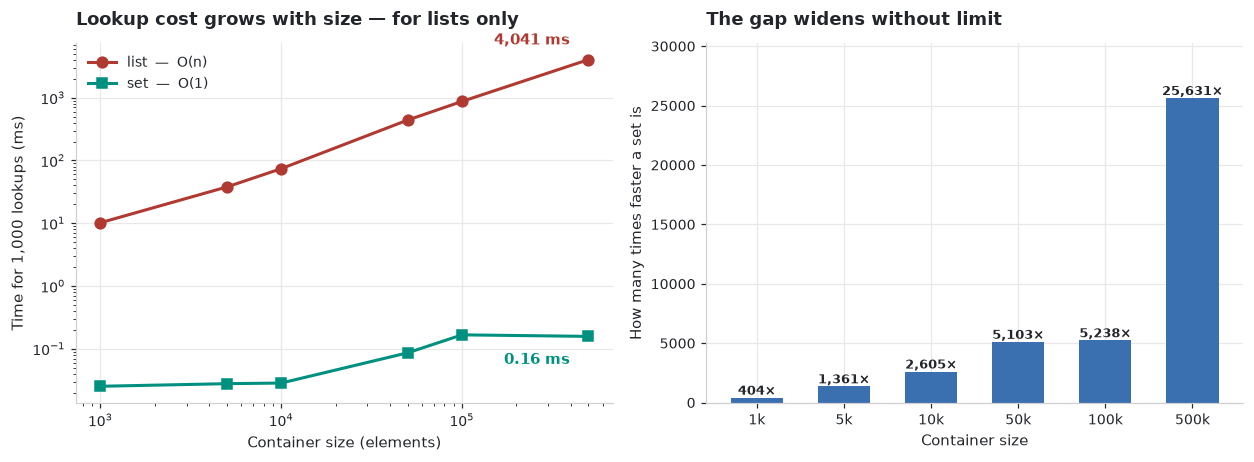

In [14]:
fig, (ax_abs, ax_ratio) = plt.subplots(1, 2, figsize=(11.5, 4.3))

# --- Left: absolute time, log scale ----------------------------------------
# A log y-axis is essential here: the two series differ by ~4 orders of
# magnitude, so on a linear axis the set line would be flat against zero.
ax_abs.plot(sizes, np.array(list_times) * 1000, marker="o",
            label="list  —  O(n)", color=COLORS["danger"])
ax_abs.plot(sizes, np.array(set_times) * 1000, marker="s",
            label="set  —  O(1)", color=COLORS["teal"])

ax_abs.set_xscale("log")
ax_abs.set_yscale("log")
ax_abs.set_xlabel("Container size (elements)")
ax_abs.set_ylabel("Time for 1,000 lookups (ms)")
ax_abs.set_title("Lookup cost grows with size — for lists only")
ax_abs.legend()

# Direct-label the endpoints so identity does not rest on colour alone.
ax_abs.annotate(f"{list_times[-1] * 1000:,.0f} ms",
                xy=(sizes[-1], list_times[-1] * 1000),
                xytext=(-12, 10), textcoords="offset points",
                color=COLORS["danger"], fontweight="bold", ha="right")
ax_abs.annotate(f"{set_times[-1] * 1000:.2f} ms",
                xy=(sizes[-1], set_times[-1] * 1000),
                xytext=(-12, -18), textcoords="offset points",
                color=COLORS["teal"], fontweight="bold", ha="right")

# --- Right: the speed-up factor --------------------------------------------
speedup = np.array(list_times) / np.array(set_times)
ax_ratio.bar([f"{s // 1000}k" for s in sizes], speedup,
             color=COLORS["primary"], width=0.6)
ax_ratio.set_xlabel("Container size")
ax_ratio.set_ylabel("How many times faster a set is")
ax_ratio.set_title("The gap widens without limit")

for i, value in enumerate(speedup):
    ax_ratio.text(i, value, f"{value:,.0f}×", ha="center", va="bottom",
                  fontsize=8.5, fontweight="bold", color=COLORS["text"])
ax_ratio.set_ylim(0, speedup.max() * 1.18)

fig.tight_layout()
plt.show()

> [!TIP]
> **The practical rule:** the moment you write `if x in some_list` *inside a
> loop*, convert the list to a set first. This one habit routinely turns a
> multi-hour job into a multi-second one.

```python
# ✘ O(n × m)
valid = load_valid_ids()                    # a list of 500,000 ids
clean = [r for r in records if r["id"] in valid]

# ✔ O(n + m) — one extra line
valid = set(load_valid_ids())
clean = [r for r in records if r["id"] in valid]
```

### The trade-off: memory

Sets and dicts buy speed with space. They keep their hash table deliberately
sparse (roughly one-third empty) so collisions stay rare.

In [15]:
n = 100_000
as_list = list(range(n))
as_set = set(as_list)
as_dict = dict.fromkeys(as_list)

from dstoolkit import format_bytes

print(f"list : {format_bytes(sys.getsizeof(as_list)):>10}")
print(f"set  : {format_bytes(sys.getsizeof(as_set)):>10}   "
      f"({sys.getsizeof(as_set) / sys.getsizeof(as_list):.1f}× the list)")
print(f"dict : {format_bytes(sys.getsizeof(as_dict)):>10}")
print("\nUsually a good trade. Worth knowing when memory is the binding constraint.")

list :  781.3 KiB
set  :    4.0 MiB   (5.2× the list)
dict :    5.0 MiB

Usually a good trade. Worth knowing when memory is the binding constraint.


## 7. Comprehensions

A comprehension builds a collection from an iterable in one expression. It is
more readable than the equivalent loop and measurably faster, because the loop
runs in C rather than in the interpreter.

```text
[ expression   for item in iterable   if condition ]
  └─ what to    └─ where the        └─ optional
     produce       items come from     filter
```

In [16]:
temperatures_c = [18.5, 22.0, 31.2, 15.8, 28.4, 35.1]

# The loop version.
loop_result = []
for temp in temperatures_c:
    if temp > 20:
        loop_result.append(temp * 9 / 5 + 32)

# The comprehension — same result, one line, no mutable accumulator.
comp_result = [t * 9 / 5 + 32 for t in temperatures_c if t > 20]

print(f"loop          : {[round(t, 1) for t in loop_result]}")
print(f"comprehension : {[round(t, 1) for t in comp_result]}")
print(f"identical     : {loop_result == comp_result}")

loop          : [71.6, 88.2, 83.1, 95.2]
comprehension : [71.6, 88.2, 83.1, 95.2]
identical     : True


### Dict and set comprehensions

In [17]:
products = ["laptop", "mouse", "monitor", "keyboard"]
prices = [1200.0, 25.0, 340.0, 85.0]

# Dict comprehension.
catalogue = {name: price for name, price in zip(products, prices, strict=True)}
print(f"catalogue : {catalogue}")

# With a filter and a transformation.
premium = {name: price * 0.9 for name, price in catalogue.items() if price > 100}
print(f"premium (10% off) : {premium}")

# Set comprehension — deduplicates automatically.
initials = {name[0] for name in products}
print(f"distinct initials : {sorted(initials)}")

catalogue : {'laptop': 1200.0, 'mouse': 25.0, 'monitor': 340.0, 'keyboard': 85.0}
premium (10% off) : {'laptop': 1080.0, 'monitor': 306.0}
distinct initials : ['k', 'l', 'm']


### Conditional expressions inside a comprehension

Note the position: a filter (`if` at the end) *removes* items; a conditional
expression (`if/else` at the front) *transforms* them. Both are useful; mixing
them up is a common slip.

In [18]:
values = [10, -5, 8, -3, 0]

filtered = [v for v in values if v > 0]                 # removes items
transformed = [v if v > 0 else 0 for v in values]       # keeps all, clips them

print(f"original    : {values}")
print(f"filtered    : {filtered}     ← 'if' at the END drops items")
print(f"transformed : {transformed}  ← 'if/else' at the FRONT maps items")

original    : [10, -5, 8, -3, 0]
filtered    : [10, 8]     ← 'if' at the END drops items
transformed : [10, 0, 8, 0, 0]  ← 'if/else' at the FRONT maps items


> [!WARNING]
> **Do not nest more than two levels.** Comprehensions stop being readable fast.
> If you need a comment to explain one, write the loop instead — clarity beats
> cleverness in code that someone will debug at 2 a.m.

In [19]:
# Two levels is the sane maximum. This flattens a nested structure:
batches = [[1, 2, 3], [4, 5], [6, 7, 8, 9]]
flat = [value for batch in batches for value in batch]

print(f"nested : {batches}")
print(f"flat   : {flat}")
print("\nRead the `for` clauses left to right, exactly as you would write the loop.")

nested : [[1, 2, 3], [4, 5], [6, 7, 8, 9]]
flat   : [1, 2, 3, 4, 5, 6, 7, 8, 9]

Read the `for` clauses left to right, exactly as you would write the loop.


## 8. The `collections` module

Four specialised containers that remove a lot of boilerplate.

### `Counter` — frequency counting in one line

In [20]:
from collections import Counter

channels = ["organic", "paid", "organic", "referral", "paid", "organic", "email"]

counts = Counter(channels)

print(f"counts        : {counts}")
print(f"most common 2 : {counts.most_common(2)}")
print(f"organic       : {counts['organic']}")
print(f"missing key   : {counts['unknown']}   ← returns 0, never raises")
print(f"total         : {counts.total()}")

counts        : Counter({'organic': 3, 'paid': 2, 'referral': 1, 'email': 1})
most common 2 : [('organic', 3), ('paid', 2)]
organic       : 3
missing key   : 0   ← returns 0, never raises
total         : 7


### `defaultdict` — no more "if key not in dict"

In [21]:
from collections import defaultdict

transactions = [
    ("ana", 120.0), ("bruno", 80.0), ("ana", 45.5),
    ("carla", 200.0), ("bruno", 15.0),
]

# ✘ The manual version.
manual: dict[str, list[float]] = {}
for name, amount in transactions:
    if name not in manual:
        manual[name] = []
    manual[name].append(amount)

# ✔ defaultdict calls the factory (`list`) automatically for a missing key.
grouped = defaultdict(list)
for name, amount in transactions:
    grouped[name].append(amount)

print(f"grouped : {dict(grouped)}")
print(f"same as manual : {dict(grouped) == manual}")

# A defaultdict(float) makes running totals equally clean.
totals = defaultdict(float)
for name, amount in transactions:
    totals[name] += amount
print(f"totals  : {dict(totals)}")

grouped : {'ana': [120.0, 45.5], 'bruno': [80.0, 15.0], 'carla': [200.0]}
same as manual : True
totals  : {'ana': 165.5, 'bruno': 95.0, 'carla': 200.0}


### `deque` — a queue with O(1) appends at *both* ends

`list.insert(0, x)` and `list.pop(0)` are **O(n)**: every remaining element must
shift. A `deque` makes both ends O(1).

In [22]:
from collections import deque

# A rolling window of the last 3 readings — `maxlen` discards old items for free.
window = deque(maxlen=3)

for reading in [10, 20, 30, 40, 50]:
    window.append(reading)
    print(f"  appended {reading:>2} → window {list(window)}")

print(f"\nThis is the pattern behind streaming moving averages: "
      f"mean = {sum(window) / len(window):.1f}")

  appended 10 → window [10]
  appended 20 → window [10, 20]
  appended 30 → window [10, 20, 30]
  appended 40 → window [20, 30, 40]
  appended 50 → window [30, 40, 50]

This is the pattern behind streaming moving averages: mean = 40.0


### `namedtuple` — records with names instead of positions

In [23]:
from collections import namedtuple

# A plain tuple forces you to remember what index 2 meant.
Measurement = namedtuple("Measurement", ["timestamp", "sensor_id", "value"])

reading = Measurement(timestamp="2024-01-15T10:30", sensor_id="S-001", value=23.4)

print(f"reading        : {reading}")
print(f"by name        : {reading.value}")
print(f"by position    : {reading[2]}   ← still works; it IS a tuple")
print(f"as a dict      : {reading._asdict()}")
print(f"immutable copy : {reading._replace(value=24.0)}")

reading        : Measurement(timestamp='2024-01-15T10:30', sensor_id='S-001', value=23.4)
by name        : 23.4
by position    : 23.4   ← still works; it IS a tuple
as a dict      : {'timestamp': '2024-01-15T10:30', 'sensor_id': 'S-001', 'value': 23.4}
immutable copy : Measurement(timestamp='2024-01-15T10:30', sensor_id='S-001', value=24.0)


> [!TIP]
> For anything more than a trivial record, prefer `@dataclass` — it supports
> type hints, defaults, methods, and mutability. Notebook 05 covers it.

## 9. Sorting

`sorted()` returns a new list; `list.sort()` sorts in place. Both accept a
`key` function that computes what to sort *by*.

In [24]:
employees = [
    {"name": "Ana", "dept": "data", "salary": 95_000},
    {"name": "Bruno", "dept": "eng", "salary": 105_000},
    {"name": "Carla", "dept": "data", "salary": 110_000},
    {"name": "Diego", "dept": "eng", "salary": 95_000},
]

# Sort by a single field.
by_salary = sorted(employees, key=lambda e: e["salary"], reverse=True)
print("By salary, descending:")
for e in by_salary:
    print(f"  {e['name']:<7} {e['dept']:<6} ${e['salary']:>7,}")

# Sort by several fields: return a tuple from the key function. Tuples compare
# element by element, so this sorts by dept, then by salary descending.
by_dept_then_salary = sorted(employees, key=lambda e: (e["dept"], -e["salary"]))
print("\nBy department, then salary descending:")
for e in by_dept_then_salary:
    print(f"  {e['dept']:<6} {e['name']:<7} ${e['salary']:>7,}")

By salary, descending:
  Carla   data   $110,000
  Bruno   eng    $105,000
  Ana     data   $ 95,000
  Diego   eng    $ 95,000

By department, then salary descending:
  data   Carla   $110,000
  data   Ana     $ 95,000
  eng    Bruno   $105,000
  eng    Diego   $ 95,000


### `operator.itemgetter` — faster and clearer than a lambda

In [25]:
from operator import itemgetter

# Equivalent to `lambda e: (e["dept"], e["salary"])`, but implemented in C.
by_dept = sorted(employees, key=itemgetter("dept", "salary"))
print([f"{e['dept']}/{e['name']}" for e in by_dept])

['data/Ana', 'data/Carla', 'eng/Diego', 'eng/Bruno']


### Sort stability

Python's sort is **stable**: items comparing equal keep their original relative
order. This is a guarantee, not an accident, and it enables a powerful technique —
sort by the least significant key first, then by the most significant.

In [26]:
# Sort by salary first, then by department. Because the sort is stable, the
# salary ordering survives inside each department group.
step_1 = sorted(employees, key=itemgetter("salary"), reverse=True)
step_2 = sorted(step_1, key=itemgetter("dept"))

print("Two-pass stable sort (salary desc, then dept asc):")
for e in step_2:
    print(f"  {e['dept']:<6} {e['name']:<7} ${e['salary']:>7,}")

Two-pass stable sort (salary desc, then dept asc):
  data   Carla   $110,000
  data   Ana     $ 95,000
  eng    Bruno   $105,000
  eng    Diego   $ 95,000


## 10. Unpacking and star expressions

In [27]:
# Basic unpacking.
first, second, third = [1, 2, 3]
print(f"{first=}, {second=}, {third=}")

# Star captures "the rest" — always as a list.
head, *rest = [1, 2, 3, 4, 5]
print(f"\n{head=}, {rest=}")

*body, last = [1, 2, 3, 4, 5]
print(f"{body=}, {last=}")

first, *middle, last = [1, 2, 3, 4, 5]
print(f"{first=}, {middle=}, {last=}")

# Swapping needs no temporary variable.
a, b = 1, 2
a, b = b, a
print(f"\nafter swap : {a=}, {b=}")

first=1, second=2, third=3

head=1, rest=[2, 3, 4, 5]
body=[1, 2, 3, 4], last=5
first=1, middle=[2, 3, 4], last=5

after swap : a=2, b=1


In [28]:
# Unpacking into a function call: * for positional, ** for keyword arguments.
def describe(name: str, dept: str, salary: int) -> str:
    return f"{name} works in {dept} earning ${salary:,}"


employee = {"name": "Ana", "dept": "data", "salary": 95_000}
print(describe(**employee))            # keys become keyword arguments

args = ["Bruno", "eng", 105_000]
print(describe(*args))                 # items become positional arguments

Ana works in data earning $95,000
Bruno works in eng earning $105,000


## 11. Exercises

### Exercise 3.1 — Pick the structure

For each requirement, name the best built-in collection and justify it in one
sentence:

1. Storing the 50 million user IDs that have already been processed, to skip duplicates.
2. Keeping the last 100 sensor readings for a moving average.
3. Mapping a country code to a country name.
4. Representing an RGB colour that must never change.
5. Counting how often each word appears in 10 000 product reviews.

### Exercise 3.2 — Fix the slow function

```python
def find_new_customers(all_ids: list[int], known_ids: list[int]) -> list[int]:
    return [i for i in all_ids if i not in known_ids]
```

With 100 000 `all_ids` and 100 000 `known_ids` this takes minutes. Rewrite it to
run in well under a second, and measure both with `%timeit` to prove it.

### Exercise 3.3 — Comprehension practice

Given `sales = [{"product": "A", "units": 10, "price": 5.0}, ...]`, write
single comprehensions that produce:

1. A list of revenues (`units * price`).
2. A dict mapping product → revenue.
3. The set of products with revenue above 100.

### Exercise 3.4 — Group without pandas

Using `defaultdict`, write `group_by_key(records, key)` that groups a list of
dicts by any field and returns `dict[Any, list[dict]]`. This is `pandas.groupby`
in eight lines — writing it once makes Module 03 much clearer.

### Exercise 3.5 — Multi-key sorting

Sort the `employees` list by department ascending, then salary descending, then
name ascending — using a **single** `sorted()` call. *Hint:* negate the numeric
field inside the key tuple.

## Key takeaways

- **Choose containers by complexity.** `list` membership is O(n); `set` and
  `dict` are O(1).
- The habit that matters: **`set()` any collection you will repeatedly test
  membership against.**
- Mutating list methods return `None`. Use `sorted()` when you want a new list.
- Tuples are records *and* the hashable sequence — they can be dict keys.
- **Comprehensions** are the default idiom for building collections; keep them
  to two levels at most.
- `Counter`, `defaultdict`, `deque`, and `namedtuple` remove whole categories of
  boilerplate.
- Python's sort is **stable**, which makes multi-pass sorting reliable.

---

**Next:** [04 · Functions & Functional Programming](04_functions_and_functional_programming.ipynb)
— signatures, closures, decorators, and generators that process files larger than RAM.